# AlgoriThemes: AI-Assisted Interpretation

**Companion notebook to:** `EDA_modelling_evaluation.ipynb`

This notebook examines the *outputs* of the selected analytical workflow rather than repeating the exploratory analysis or comparison of LDA, NMF, K-Means and BERTopic. It tests how identified topics are translated into descriptive labels and broader themes using Gemini, how RoBERTa adds sentiment information, and how the combined evidence can support research reporting.

**Research objective covered:** To use large language models to generate meaningful topic labels and group related topics into broader themes.


## 1. Notebook setup and analytical workflow

The workflow is:

**Load and prepare responses → BERTopic topic discovery → select representative responses → Gemini topic naming → conditional theme grouping → RoBERTa sentiment classification → compare sentiment across topics → Gemini report and recommendations → assess practical usefulness.**

The modelling approach was selected in the companion notebook. Here, we retain the application’s analytical functions but call them **directly**, without its Streamlit interface or GPU-hosting client.



In [2]:
from pathlib import Path
import sys

# Find the folder containing the application's Python modules
current_dir = Path.cwd()

for parent in [current_dir, *current_dir.parents]:
    for candidate in [parent, parent / "AlgoriThemes"]:
        if (candidate / "data_processing.py").exists():
            sys.path.insert(0, str(candidate))
            print(f"Modules found in: {candidate}")
            break
    else:
        continue
    break
else:
    raise FileNotFoundError(
        "Could not locate data_processing.py. Check your project folder."
    )


Modules found in: c:\Users\laureennyambura\Desktop\Data Science_Moringa\module_6\AlgoriThemes\AlgoriThemes


In [3]:
from pathlib import Path
import json
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sentence_transformers import SentenceTransformer

from data_processing import clean_text, clean_for_bertopic
from topic_analysis import run_bertopic, sample_for_gemini
from sentiment_analysis import predict_sentiment, SENTIMENT_CONFIG
from gemini_analysis import generate_topic_names, generate_themes, generate_report
from outputs import prepare_report_evidence

pd.set_option("display.max_colwidth", 110)

### 1.1 Dataset configuration

These settings are carried over from the research notebook. The optional identifier is retained for traceability; it is **not** used to remove duplicates, matching the research notebook's preparation approach. The original survey question is supplied to Gemini as context for interpreting responses.

In [4]:
CONFIG = {
    "run_name": "faculty_support",
    "file_path": "C:/Users/laureennyambura/Desktop/Data Science_Moringa/module_6/AlgoriThemes/AlgoriThemes/demo_datasets/TopicModellingStudentFeedbackData.xlsx",
    "sheet_name": 0,
    "response_column": "FacultySupportResponse",
    "id_column": "Subject Code",
    "survey_question": "What one action can professors take to best support students in their classes?",
    "min_words": 3,
    "embedding_model": "all-MiniLM-L6-v2",
    "random_state": 42,
    "output_dir": "outputs/faculty_support/ai_interpretation",
}

FILE_PATH = Path(CONFIG["file_path"])
RESPONSE_COLUMN = CONFIG["response_column"]
ID_COLUMN = CONFIG["id_column"]
SURVEY_QUESTION = CONFIG["survey_question"]
OUTPUT_DIR = Path(CONFIG["output_dir"])
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Dataset: {FILE_PATH}")
print(f"Response column: {RESPONSE_COLUMN}")
print(f"Respondent identifier: {ID_COLUMN}")

Dataset: C:\Users\laureennyambura\Desktop\Data Science_Moringa\module_6\AlgoriThemes\AlgoriThemes\demo_datasets\TopicModellingStudentFeedbackData.xlsx
Response column: FacultySupportResponse
Respondent identifier: Subject Code


## 2. Load and prepare the survey responses

As in the first notebook, blank responses and responses containing fewer than three words after preprocessing are excluded. `clean_text` is used to determine eligibility; `bert_text` preserves the wording needed for semantic modelling and sentiment analysis.

We **do not** repeat exploratory plots, vocabulary analysis or model comparison here. The purpose of this check is simply to establish the sample analysed in the subsequent sections.

In [5]:
if not FILE_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {FILE_PATH.resolve()}. "
        "Place the dataset at this path or update CONFIG['file_path']."
    )

if FILE_PATH.suffix.lower() == ".csv":
    raw_df = pd.read_csv(FILE_PATH)
else:
    raw_df = pd.read_excel(FILE_PATH, sheet_name=CONFIG["sheet_name"])

required_columns = [RESPONSE_COLUMN] + ([ID_COLUMN] if ID_COLUMN else [])
missing_columns = [c for c in required_columns if c not in raw_df.columns]
if missing_columns:
    raise KeyError(f"Columns missing from dataset: {missing_columns}")

prepared = raw_df.copy()
prepared = prepared.dropna(subset=[RESPONSE_COLUMN])
prepared = prepared.loc[
    prepared[RESPONSE_COLUMN].astype(str).str.strip().ne("")
].copy().reset_index(drop=True)

prepared["clean_text"] = prepared[RESPONSE_COLUMN].map(clean_text)
prepared["bert_text"] = prepared[RESPONSE_COLUMN].map(clean_for_bertopic)
prepared["word_count"] = prepared["clean_text"].str.split().str.len()

model_df = prepared.loc[
    prepared["word_count"] >= CONFIG["min_words"]
].copy().reset_index(drop=True)
model_df.insert(0, "response_id", np.arange(len(model_df)))

preparation_summary = pd.DataFrame({
    "Stage": ["Original rows", "Nonblank responses", "Eligible responses", "Short responses excluded"],
    "Count": [len(raw_df), len(prepared), len(model_df), len(prepared) - len(model_df)],
})
display(preparation_summary)
display(model_df[[c for c in [ID_COLUMN, RESPONSE_COLUMN, "clean_text", "bert_text"] if c]].head(5))

if len(model_df) < 30:
    raise ValueError("Topic discovery requires at least 30 eligible open-ended responses.")

,Stage,Count
0,Original rows,1707
1,Nonblank responses,1676
2,Eligible responses,1603
3,Short responses excluded,73


,Subject Code,FacultySupportResponse,clean_text,bert_text
0,1,"Better handwriting, hard to follow lecture slides some times",better handwriting hard follow lecture slide time,"Better handwriting, hard to follow lecture slides some times"
1,2,Variety of office hours so that all can get help when needed,variety office hour get help needed,Variety of office hours so that all can get help when needed
2,3,"Better lecture, no more ""is that good?""",better lecture good,"Better lecture, no more ""is that good?"""
3,4,Online resources; post more notes on line,online resource post note line,Online resources; post more notes on line
4,5,It would be better if we can have an equation sheet,would better equation sheet,It would be better if we can have an equation sheet


**How to interpret this output:** The table documents the denominator for all later percentages. The eligible-response count may differ from the original dataset size because missing, blank and very short responses are not analysed. We retain the original text for interpretation rather than using the aggressively cleaned version as the model input.

## 3. Topic discovery using the selected BERTopic model

BERTopic was selected in the companion notebook after comparison with LDA, NMF and K-Means. This section applies the selected approach to the eligible responses. Sentence embeddings capture semantic meaning; BERTopic groups similar responses and extracts topic keywords.

The implementation below reuses `run_bertopic()` from the supplied application code, including its adaptive minimum cluster size and reassignment of outliers. Unlike the earlier comparison experiment, the number of topics is discovered from the data rather than imposed in advance.

In [6]:
embedding_model = SentenceTransformer(CONFIG["embedding_model"])
documents = model_df["bert_text"].astype(str).tolist()

topic_ids, topic_table, bertopic_model, model_summary, embeddings = run_bertopic(
    docs=documents,
    embedding_model=embedding_model,
    seed=CONFIG["random_state"],
    top_n_words=10,
)

model_df["topic"] = topic_ids
print("Topic discovery summary:")
display(pd.DataFrame([model_summary]))
display(topic_table)

2026-11-18 16:01:57,874 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


Topic discovery summary:


,answers,min_cluster_size,topics_found,outliers_assigned,outliers_left
0,1603,16,24,514,0


,Topic,Answers,Share %,Keywords,Example answers
0,0,146,9.1,"examples, example, problems, class, concepts, explain","More hand written examples during class, and working fully though problems. Specifically complex examples ..."
1,1,142,8.9,"lectures, recorded, lecture, recordings, recording, recorded lectures",Providing recorded lectures is always helpful | Provide good recording for the lectures | Recording the le...
2,2,115,7.2,"office, hours, office hours, available, questions, email",Provide more office hours. | Provide more office hours. | Providing office hours.
3,3,112,7.0,"office, hours, office hours, students, help, class",I think one action that professors can take to best support me in my classes is to have consistent office ...
4,5,98,6.1,"students, professors, class, professor, support, best","If professors are actively communicating with their students , i.e. updates on class schedule, giving plen..."
5,4,97,6.1,"exams, practice, exam, practice exams, tests, provide",Provide lot of practice exams | Provide more practice exams | Provide more practice exams
6,10,88,5.5,"lectures, lecture, engaging, class, make, make lectures",Making sure that lectures are clear and effective. That their explanations are also very clear. Try to mak...
7,17,78,4.9,"course, textbook, provide, material, class, topics","Provide written materials that contain the subject matter of the course. These may include lecture slides,..."
8,13,73,4.6,"grading, assignments, expectations, students, clear, class",Be more clear on what they want when grading assignments. | Be transparent about grading policies and expe...
9,7,59,3.7,"dates, assignments, deadlines, schedule, quarter, assignment",a very clear schedule with all due dates and assignments. | Have a very clear schedule of when assignments...


**Interpretation:** Each topic represents a group of semantically related responses, not necessarily a distinct concern expressed by every respondent. `Answers` gives the number of responses assigned to a topic; `Share %` uses all eligible responses as the denominator. Keywords and example answers help interpret the clusters but are not, by themselves, reliable final topic labels.

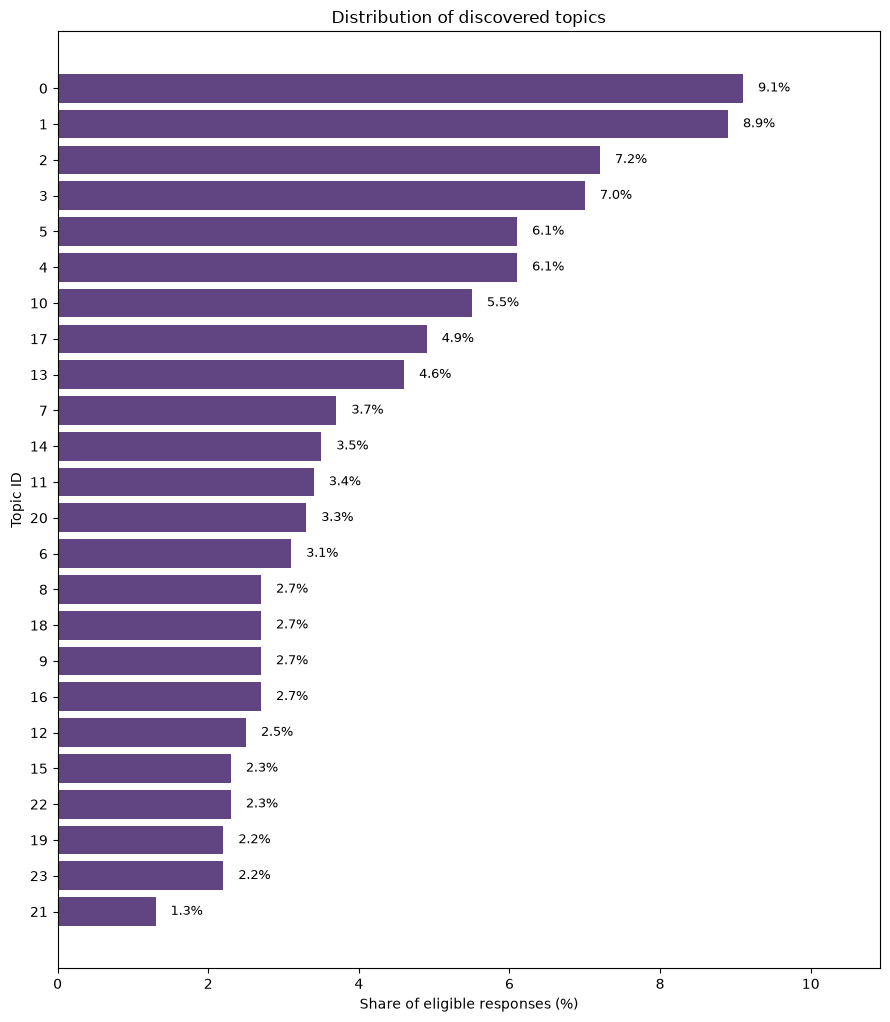

In [7]:
topic_plot = topic_table.sort_values("Answers", ascending=True)
fig, ax = plt.subplots(figsize=(9, max(4, len(topic_plot) * 0.43)))
ax.barh(topic_plot["Topic"].astype(str), topic_plot["Share %"], color="#604582")
ax.set_xlabel("Share of eligible responses (%)")
ax.set_ylabel("Topic ID")
ax.set_title("Distribution of discovered topics")
for y, value in enumerate(topic_plot["Share %"]):
    ax.text(value + 0.2, y, f"{value:.1f}%", va="center", fontsize=9)
ax.set_xlim(0, max(topic_plot["Share %"].max() * 1.20, 1))
plt.tight_layout()
plt.show()

## 4. Selecting Survey Responses for Gemini Analysis

After BERTopic identifies the topics, the next step is to select a sample of responses from each topic for interpretation using Gemini.

Rather than sending every survey response to Gemini, we select approximately **25% of the responses** across the identified topics.

The sampling process combines two approaches:

- **Representative sampling (50%):** Selects responses that are most similar to the overall meaning of their assigned topic.
- **Random sampling (50%):** Selects additional responses randomly from each topic to capture different perspectives that may not appear among the most representative responses.

The process also aims to include at least five responses per topic, where possible.

These selected responses, together with the topic keywords and the number of responses assigned to each topic, are provided to Gemini. Gemini then uses this information to generate meaningful topic names and descriptions.

In [8]:
gemini_samples = sample_for_gemini(
    model_df=model_df,
    embeddings=embeddings,
    response_column=RESPONSE_COLUMN,
    sample_fraction=0.25,
    min_per_topic=5,
    representative_fraction=0.50,
    seed=CONFIG["random_state"],
)

gemini_topic_data = []
for _, row in topic_table.iterrows():
    topic_id = int(row["Topic"])
    if topic_id == -1:
        continue
    examples = gemini_samples.loc[
        gemini_samples["topic_id"].eq(topic_id), "response"
    ].astype(str).tolist()
    gemini_topic_data.append({
        "topic_id": topic_id,
        "total_responses": int(row["Answers"]),
        "keywords": row["Keywords"],
        "sample_size": len(examples),
        "sample_responses": examples,
    })

print(f"Responses sampled for Gemini: {len(gemini_samples):,}")
display(gemini_samples.groupby("topic_id").size().rename("Sampled responses").reset_index())
display(gemini_samples.head(10))

Responses sampled for Gemini: 401


,topic_id,Sampled responses
0,0,37
1,1,36
2,2,29
3,3,28
4,4,24
5,5,25
6,6,12
7,7,15
8,8,11
9,9,11


,topic_id,response
0,0,"More hand written examples during class, and working fully though problems. Specifically complex examples ..."
1,0,Clearly explaining how they solve example problems in class and why they take the steps that they do.
2,0,Using examples in explaining concepts.
3,0,Give plenty of examples to clearly explain the topics covered in class and to give insight into homework p...
4,0,"Do example problems. Understanding the concepts is the easy part, the hard part is applying them,"
5,0,Provide in depth examples of problems in class.
6,0,Provide a lot of in class examples during lecture.
7,0,Providing examples for any concepts that are taught in or out of class.
8,0,Do more examples in class and work through them
9,0,"Doing, showing examples in class and showing how to solve those examples."


**What this output demonstrates:** Topic interpretation is anchored in respondent statements rather than generated solely from a word list. Sampling reduces the amount of text sent to Gemini, but it also means that the model may not see every nuance in a topic. Human review against additional original responses remains important.

## 5. Gemini-generated topic names and descriptions

Gemini receives the evidence prepared above and returns a short topic name and explanation for each original topic ID. The existing function checks that every topic is named exactly once.

**Evaluation question:** Do the generated names reflect what respondents are actually discussing? Compare the label, description and sample responses, especially for topics containing mixed suggestions.

In [9]:
# This cell makes a real Gemini API call through your existing gemini_analysis.py.
topic_names = generate_topic_names(gemini_topic_data, SURVEY_QUESTION)

topic_names = topic_names.sort_values("topic_id").reset_index(drop=True)
named_topics = (
    topic_names.merge(
        topic_table[["Topic", "Answers", "Share %", "Keywords"]],
        left_on="topic_id", right_on="Topic", validate="one_to_one"
    )
    .drop(columns="Topic")
    .sort_values("Answers", ascending=False)
)
display(named_topics[["topic_id", "topic_name", "description", "Answers", "Share %", "Keywords"]])

,topic_id,topic_name,description,Answers,Share %,Keywords
0,0,Working Through Example Problems in Class,Respondents request that professors solve and thoroughly explain step-by-step example problems during lect...,146,9.1,"examples, example, problems, class, concepts, explain"
1,1,Providing Recorded Lectures,Respondents urge professors to record live lectures and upload video recordings promptly to enable flexibl...,142,8.9,"lectures, recorded, lecture, recordings, recording, recorded lectures"
2,2,Increasing Office Hour Availability,Respondents emphasize the need for more frequent office hours and prompt responses to student questions vi...,115,7.2,"office, hours, office hours, available, questions, email"
3,3,Scheduling Flexible Office Hours,Respondents request office hours scheduled at varied times to prevent conflicts with other classes and acc...,112,7.0,"office, hours, office hours, students, help, class"
5,5,Fostering Student Engagement and Empathy,"Respondents encourage professors to be enthusiastic, approachable, interactive, and empathetic toward stud...",98,6.1,"students, professors, class, professor, support, best"
4,4,Providing Practice Exams and Study Materials,"Respondents ask for sample exams, practice tests, and detailed study guides to help them prepare effective...",97,6.1,"exams, practice, exam, practice exams, tests, provide"
10,10,Delivering Interactive and Engaging Lectures,"Respondents express a desire for engaging, interactive lectures that feature active participation, live po...",88,5.5,"lectures, lecture, engaging, class, make, make lectures"
17,17,Providing Clear Course Materials and Outlines,"Respondents advocate for comprehensive reading guides, syllabus alignment, and connecting course content t...",78,4.9,"course, textbook, provide, material, class, topics"
13,13,Clarifying Grading Policies and Expectations,"Respondents call for transparent grading rubrics, explicit assignment expectations, and realistic course w...",73,4.6,"grading, assignments, expectations, students, clear, class"
7,7,Communicating Due Dates and Deadlines,"Respondents highlight the importance of clear assignment schedules, consistent due date reminders, and fle...",59,3.7,"dates, assignments, deadlines, schedule, quarter, assignment"


**How to assess this output:** A useful label should be specific, understandable to a nontechnical researcher and supported by the original responses. A plausible-sounding name is not necessarily accurate. Inspect whether the description captures the dominant issue and whether meaningful differences between respondents have been overlooked.

In [10]:
# Inspect a small sample of original responses beneath each generated label.
review_rows = []
for topic_id in sorted(topic_names["topic_id"]):
    label = topic_names.set_index("topic_id").loc[topic_id, "topic_name"]
    sample = gemini_samples.loc[
        gemini_samples["topic_id"].eq(topic_id), "response"
    ].head(3)
    for response in sample:
        review_rows.append({
            "Topic ID": topic_id,
            "Gemini topic name": label,
            "Original response": response,
        })
display(pd.DataFrame(review_rows))

,Topic ID,Gemini topic name,Original response
0,0,Working Through Example Problems in Class,"More hand written examples during class, and working fully though problems. Specifically complex examples ..."
1,0,Working Through Example Problems in Class,Clearly explaining how they solve example problems in class and why they take the steps that they do.
2,0,Working Through Example Problems in Class,Using examples in explaining concepts.
3,1,Providing Recorded Lectures,Providing recorded lectures is always helpful
4,1,Providing Recorded Lectures,Provide good recording for the lectures
...,...,...,...
67,22,Pacing Lectures and Managing Time,Go slightly slower in lectures and emphasize on the most important concepts
68,22,Pacing Lectures and Managing Time,Taking more time to get through the lecture material. A lot of material was packed into each lecture and i...
69,23,Maintaining Flexibility in Online Courses,"Be organized. Having a set, organized schedule with lectures, labs, quiz sections, homework due dates, and..."
70,23,Maintaining Flexibility in Online Courses,"Since online, the teaching may not be as good as in-class, so holding more office hours would be a big help"


## 6. Group related topics into broader themes (when appropriate)

A **topic** is a relatively specific issue or idea; a **theme** brings together genuinely related topics. Gemini considers the topic names, descriptions, keywords and sampled responses before proposing groups.

The application's rule is to perform this additional grouping only when **more than eight topics** are identified. When eight or fewer topics are found, we retain the individual topics and do not invent a theme hierarchy.

In [11]:
theme_input = []
for item in gemini_topic_data:
    match = topic_names.loc[topic_names["topic_id"].eq(item["topic_id"])].iloc[0]
    theme_input.append({
        "topic_id": item["topic_id"],
        "topic_name": match["topic_name"],
        "topic_description": match["description"],
        "total_responses": item["total_responses"],
        "keywords": item["keywords"],
        "sample_responses": item["sample_responses"],
    })

themes_generated = len(gemini_topic_data) > 8
if themes_generated:
    theme_groups = generate_themes(theme_input, SURVEY_QUESTION)
    theme_mapping = topic_names.merge(theme_groups, on="topic_id", validate="one_to_one")
    display(theme_mapping[["topic_id", "topic_name", "theme_name", "theme_description"]])
else:
    theme_groups = None
    theme_mapping = topic_names.copy()
    theme_mapping["theme_name"] = pd.NA
    theme_mapping["theme_description"] = pd.NA
    print(
        f"Theme grouping skipped: {len(gemini_topic_data)} topics identified "
        "(grouping requires more than eight)."
    )

,topic_id,topic_name,theme_name,theme_description
0,0,Working Through Example Problems in Class,Effective Lecture Preparation and In-Class Instruction,"Topics focusing on the real-time pedagogical execution of lectures, including step-by-step example problem..."
1,1,Providing Recorded Lectures,Online and Remote Learning Adaptation,"Topics focused on facilitating virtual and asynchronous education, such as posting recorded lectures promp..."
2,2,Increasing Office Hour Availability,"Instructor Accessibility, Flexible Office Hours, and Empathy","Topics emphasizing out-of-class instructor support, frequent and non-conflicting office hour availability,..."
3,3,Scheduling Flexible Office Hours,"Instructor Accessibility, Flexible Office Hours, and Empathy","Topics emphasizing out-of-class instructor support, frequent and non-conflicting office hour availability,..."
4,4,Providing Practice Exams and Study Materials,"Practice Materials, Assessment Strategies, and Exam Preparation","Topics highlighting concrete academic practice tools to help students prepare for evaluations, including p..."
5,5,Fostering Student Engagement and Empathy,"Instructor Accessibility, Flexible Office Hours, and Empathy","Topics emphasizing out-of-class instructor support, frequent and non-conflicting office hour availability,..."
6,6,Organizing Course Content on Canvas,"Course Organization, Alignment, and Explicit Expectations","Topics dealing with administrative clarity and curriculum structure, including well-organized Canvas pages..."
7,7,Communicating Due Dates and Deadlines,"Course Organization, Alignment, and Explicit Expectations","Topics dealing with administrative clarity and curriculum structure, including well-organized Canvas pages..."
8,8,Improving Zoom Lecture Delivery,Online and Remote Learning Adaptation,"Topics focused on facilitating virtual and asynchronous education, such as posting recorded lectures promp..."
9,9,Providing Clear Guidance on Lab Assignments,"Course Organization, Alignment, and Explicit Expectations","Topics dealing with administrative clarity and curriculum structure, including well-organized Canvas pages..."


**Interpretation:** Broader themes can simplify reporting when there are many topics. They should not be treated as objectively established categories: Gemini's proposed relationships need to be checked against the responses. When grouping is skipped, the topic-level results remain useful and no artificial themes are reported.

## 7. Attach interpreted topics to individual responses

The output becomes useful for analysis when every eligible response can be traced to its topic, and—where generated—its broader theme. This produces an auditable *coded response dataset*, which can be filtered, counted or reviewed by a human analyst.

In [12]:
topic_results_df = model_df.merge(
    theme_mapping,
    left_on="topic",
    right_on="topic_id",
    how="left",
    validate="many_to_one",
)
topic_results_df["topic_name"] = topic_results_df["topic_name"].fillna("Unassigned")

topic_columns = [
    c for c in [ID_COLUMN, RESPONSE_COLUMN, "topic", "topic_name", "theme_name"]
    if c in topic_results_df.columns
]
display(topic_results_df[topic_columns].head(12))

topic_distribution = (
    topic_results_df.groupby(["topic", "topic_name"], dropna=False)
    .size().reset_index(name="Responses")
)
topic_distribution["Percentage"] = (
    100 * topic_distribution["Responses"] / len(topic_results_df)
).round(1)
display(topic_distribution.sort_values("Responses", ascending=False))

,Subject Code,FacultySupportResponse,topic,topic_name,theme_name
0,1,"Better handwriting, hard to follow lecture slides some times",15,Sharing Lecture Slides Before Class,Effective Lecture Preparation and In-Class Instruction
1,2,Variety of office hours so that all can get help when needed,2,Increasing Office Hour Availability,"Instructor Accessibility, Flexible Office Hours, and Empathy"
2,3,"Better lecture, no more ""is that good?""",10,Delivering Interactive and Engaging Lectures,Effective Lecture Preparation and In-Class Instruction
3,4,Online resources; post more notes on line,20,Posting Detailed Lecture Notes,Effective Lecture Preparation and In-Class Instruction
4,5,It would be better if we can have an equation sheet,0,Working Through Example Problems in Class,Effective Lecture Preparation and In-Class Instruction
5,6,Be specific as to what will be asked for on the exam,4,Providing Practice Exams and Study Materials,"Practice Materials, Assessment Strategies, and Exam Preparation"
6,7,Make class smaller,22,Pacing Lectures and Managing Time,Effective Lecture Preparation and In-Class Instruction
7,8,Make document summarizing all important equations and scenarios; discuss labs,9,Providing Clear Guidance on Lab Assignments,"Course Organization, Alignment, and Explicit Expectations"
8,9,Email class notes after every class.,20,Posting Detailed Lecture Notes,Effective Lecture Preparation and In-Class Instruction
9,11,Take the time to explain concepts more in depth so that it will be easier to understand,0,Working Through Example Problems in Class,Effective Lecture Preparation and In-Class Instruction


,topic,topic_name,Responses,Percentage
0,0,Working Through Example Problems in Class,146,9.1
1,1,Providing Recorded Lectures,142,8.9
2,2,Increasing Office Hour Availability,115,7.2
3,3,Scheduling Flexible Office Hours,112,7.0
5,5,Fostering Student Engagement and Empathy,98,6.1
4,4,Providing Practice Exams and Study Materials,97,6.1
10,10,Delivering Interactive and Engaging Lectures,88,5.5
17,17,Providing Clear Course Materials and Outlines,78,4.9
13,13,Clarifying Grading Policies and Expectations,73,4.6
7,7,Communicating Due Dates and Deadlines,59,3.7


**Organisational relevance:** Instead of manually reading every answer before identifying broad patterns, analysts receive a first-pass coding structure and a response-level audit trail. The original responses remain accessible, allowing researchers to verify or revise the automated interpretation.

## 8. RoBERTa sentiment analysis

The selected sentiment classifier is `cardiffnlp/twitter-roberta-base-sentiment-latest`, which assigns each eligible response one of three labels: **Positive, Neutral or Negative**. We classify the same responses used for topic modelling, preserving comparability between the two outputs.

The model also returns a maximum class probability (shown as a confidence score) and flags responses below the configured **70%** threshold for review. This probability is **not a calibrated accuracy measure**, and the label is not ground truth.

In [13]:
sentiment_predictions = predict_sentiment(
    topic_results_df["bert_text"].astype(str).tolist()
)
if len(sentiment_predictions) != len(topic_results_df):
    raise AssertionError("Sentiment predictions and topic assignments do not align.")

analysis_df = pd.concat(
    [topic_results_df.reset_index(drop=True), sentiment_predictions.reset_index(drop=True)],
    axis=1,
)

display(
    analysis_df[
        [c for c in [ID_COLUMN, RESPONSE_COLUMN, "topic_name",
                     "sentiment", "confidence_score", "review_flag"]
         if c in analysis_df.columns]
    ].head(12)
)

Some weights of the model checkpoint at cardiffnlp/twitter-roberta-base-sentiment-latest were not used when initializing RobertaForSequenceClassification: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
You're using a RobertaTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


,Subject Code,FacultySupportResponse,topic_name,sentiment,confidence_score,review_flag
0,1,"Better handwriting, hard to follow lecture slides some times",Sharing Lecture Slides Before Class,Neutral,53.8,Review
1,2,Variety of office hours so that all can get help when needed,Increasing Office Hour Availability,Neutral,78.7,Classified
2,3,"Better lecture, no more ""is that good?""",Delivering Interactive and Engaging Lectures,Positive,55.6,Review
3,4,Online resources; post more notes on line,Posting Detailed Lecture Notes,Neutral,89.8,Classified
4,5,It would be better if we can have an equation sheet,Working Through Example Problems in Class,Neutral,66.1,Review
5,6,Be specific as to what will be asked for on the exam,Providing Practice Exams and Study Materials,Neutral,85.4,Classified
6,7,Make class smaller,Pacing Lectures and Managing Time,Neutral,62.4,Review
7,8,Make document summarizing all important equations and scenarios; discuss labs,Providing Clear Guidance on Lab Assignments,Neutral,83.7,Classified
8,9,Email class notes after every class.,Posting Detailed Lecture Notes,Neutral,85.1,Classified
9,11,Take the time to explain concepts more in depth so that it will be easier to understand,Working Through Example Problems in Class,Neutral,52.7,Review


### 8.1 Distribution of predicted sentiment

This distribution describes the *model's classifications* of the responses; it does not directly measure satisfaction. In the companion research notebook, the faculty-support question produced many neutral predictions because it asks respondents for actions or suggestions rather than a satisfaction rating. The new run below calculates the distribution afresh.

,Sentiment,Responses,Percentage
0,Positive,353,22.0
1,Neutral,1127,70.3
2,Negative,123,7.7


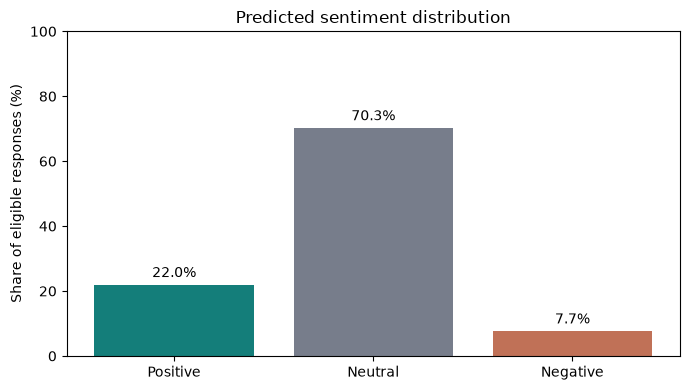

In [14]:
sentiment_order = ["Positive", "Neutral", "Negative"]
sentiment_dist = (
    analysis_df["sentiment"].value_counts()
    .reindex(sentiment_order, fill_value=0)
    .rename_axis("Sentiment").reset_index(name="Responses")
)
sentiment_dist["Percentage"] = (
    100 * sentiment_dist["Responses"] / len(analysis_df)
).round(1)
display(sentiment_dist)

fig, ax = plt.subplots(figsize=(7, 4))
colors = {"Positive": "#147E7A", "Neutral": "#777D8B", "Negative": "#C07157"}
bars = ax.bar(
    sentiment_dist["Sentiment"],
    sentiment_dist["Percentage"],
    color=[colors[s] for s in sentiment_dist["Sentiment"]],
)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_ylabel("Share of eligible responses (%)")
ax.set_title("Predicted sentiment distribution")
ax.set_ylim(0, max(100, sentiment_dist["Percentage"].max() * 1.12))
plt.tight_layout()
plt.show()

### 8.2 Prediction confidence and review flags

The review flag identifies responses for which the model's highest class probability is below 70%. It is a **triage indicator**, not proof that higher-scoring predictions are correct. These cases are useful candidates for human inspection, especially where suggestions are neutral in tone or a response expresses mixed views.

In [15]:
confidence_summary = analysis_df.groupby("sentiment", dropna=False).agg(
    Responses=("sentiment", "size"),
    Median_confidence_pct=("confidence_score", "median"),
    Review_flags=("review_flag", lambda x: int((x == "Review").sum())),
).reset_index()
confidence_summary["Review_flag_pct"] = (
    100 * confidence_summary["Review_flags"] / confidence_summary["Responses"]
).round(1)
display(confidence_summary)

display(
    analysis_df.loc[analysis_df["review_flag"].eq("Review"),
                    [RESPONSE_COLUMN, "topic_name", "sentiment", "confidence_score"]]
    .sort_values("confidence_score")
    .head(10)
)

,sentiment,Responses,Median_confidence_pct,Review_flags,Review_flag_pct
0,Negative,123,65.5,82,66.7
1,Neutral,1127,75.9,414,36.7
2,Positive,353,75.6,147,41.6


,FacultySupportResponse,topic_name,sentiment,confidence_score
134,Better and more hours for office hours. I usually can't make the section they set up.,Increasing Office Hour Availability,Neutral,42.3
1414,"Something that I have found to be helpful is when professors drop the lowest grade in a category, whether ...",Clarifying Grading Policies and Expectations,Positive,42.7
899,be engaging... show some cool live examples or something. dry zoom lectures are so last month.,Improving Zoom Lecture Delivery,Neutral,45.1
670,It would be a lot more better if the labs were group work. I think we all had a hard time figuring out the...,Providing Clear Guidance on Lab Assignments,Negative,45.1
270,Having office hours at various times is helpful. It's always frustrating when the only office hours are du...,Scheduling Flexible Office Hours,Negative,47.0
546,Don't overload us with work because we are sitting at our computer all day already watching lectures.,Supporting Students in Remote Learning,Neutral,47.5
539,Give us less homework,Aligning Homework with Course Content,Negative,47.7
973,Make it less stressful,Increasing Office Hour Availability,Neutral,47.7
582,One action professors at university can take is not lecturing. Lecturing is important but only lecturing w...,Fostering Student Engagement and Empathy,Negative,47.9
203,"Be engaged with how the students learn the material and interested in knowing what concepts are easier, mo...",Fostering Student Engagement and Empathy,Neutral,48.2


## 9. Combine topic and sentiment findings

Topic modelling answers **what respondents are discussing**; sentiment classification adds a tentative indication of **how the wording is expressed**. Comparing sentiment *within each topic* can reveal where responses are mixed, predominantly neutral or more strongly evaluative.

Percentages below use each topic's assigned-response count as the denominator. They should not be interpreted as the proportion of all respondents who hold an opinion about a particular issue.

,topic,topic_name,sentiment,Responses,Topic total,Within topic (%)
0,0,Working Through Example Problems in Class,Negative,9,146,6.2
1,0,Working Through Example Problems in Class,Neutral,124,146,84.9
2,0,Working Through Example Problems in Class,Positive,13,146,8.9
3,1,Providing Recorded Lectures,Negative,13,142,9.2
4,1,Providing Recorded Lectures,Neutral,94,142,66.2
...,...,...,...,...,...,...
64,22,Pacing Lectures and Managing Time,Neutral,26,37,70.3
65,22,Pacing Lectures and Managing Time,Positive,3,37,8.1
66,23,Maintaining Flexibility in Online Courses,Negative,8,35,22.9
67,23,Maintaining Flexibility in Online Courses,Neutral,18,35,51.4


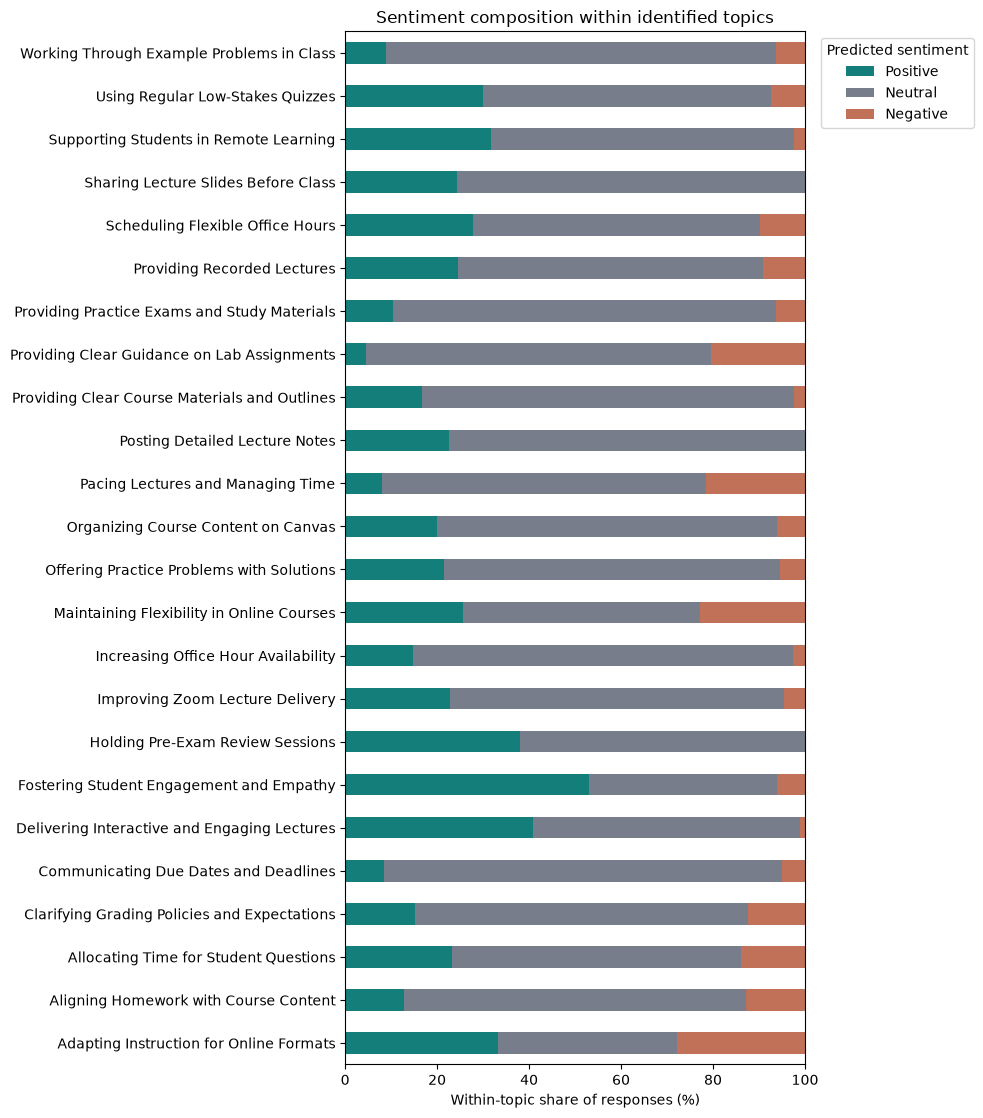

In [16]:
sentiment_by_topic = (
    analysis_df.groupby(["topic", "topic_name", "sentiment"], dropna=False)
    .size().reset_index(name="Responses")
)
sentiment_by_topic["Topic total"] = (
    sentiment_by_topic.groupby("topic")["Responses"].transform("sum")
)
sentiment_by_topic["Within topic (%)"] = (
    100 * sentiment_by_topic["Responses"] / sentiment_by_topic["Topic total"]
).round(1)
display(sentiment_by_topic.sort_values(["topic", "sentiment"]))

matrix = (
    sentiment_by_topic.pivot_table(
        index="topic_name", columns="sentiment",
        values="Within topic (%)", aggfunc="sum", fill_value=0
    )
    .reindex(columns=sentiment_order, fill_value=0)
)
ax = matrix.plot(
    kind="barh", stacked=True, figsize=(10, max(4.5, len(matrix) * 0.47)),
    color=[colors[s] for s in sentiment_order]
)
ax.set_xlim(0, 100)
ax.set_xlabel("Within-topic share of responses (%)")
ax.set_ylabel("")
ax.set_title("Sentiment composition within identified topics")
ax.legend(title="Predicted sentiment", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Interpretation:** A topic with many neutral responses can still contain important recommendations or concerns. A negative prediction does not establish that a respondent is dissatisfied with every issue in their answer. Use these charts to decide where to inspect the original responses, not to infer causation or measure programme performance directly.

## 10. Test Gemini-generated reporting and recommendations

The supplied `gemini_analysis.py` includes `generate_report()`, which converts structured topic/theme evidence into an executive summary, overview of findings, integrated key findings and actionable recommendations.

This report function is **theme-based**. To stay consistent with the application's rule, we run it only when broader themes were generated. If eight or fewer topics were identified, the notebook retains topic-level results and explicitly skips this theme-based report rather than fabricating themes.

Recommendations are generated from the evidence, not from the sentiment model alone. They must be checked for fidelity to the actual responses and for practicality in the survey context.

In [17]:
report = None
report_evidence = None
quote_bank = {}

if themes_generated:
    # Use the topic-only result to build the thematic evidence.
    # This avoids the legacy sentiment-report branch in outputs.py.
    report_inputs = {
        "response_explorer": topic_results_df,
        "theme_input": theme_input,
        "survey_question": SURVEY_QUESTION,
    }
    report_evidence, quote_bank = prepare_report_evidence(
        report_inputs, survey_question=SURVEY_QUESTION, analysis_type="topic"
    )
    print("Themes included in report evidence:", len(report_evidence["themes"]))
    print("Verifiable source quotations:", len(quote_bank))
    display(pd.DataFrame([
        {
            "Theme": theme["theme_name"],
            "Responses": theme["response_count"],
            "Percentage": theme["percentage"],
        }
        for theme in report_evidence["themes"]
    ]).sort_values("Responses", ascending=False))
else:
    print(
        "Theme-based report not generated: this run identified eight or fewer topics. "
        "Topic names, response coding and sentiment outputs remain available."
    )

Themes included in report evidence: 5
Verifiable source quotations: 401


,Theme,Responses,Percentage
1,Effective Lecture Preparation and In-Class Instruction,404,25.2
0,"Course Organization, Alignment, and Explicit Expectations",359,22.4
2,"Instructor Accessibility, Flexible Office Hours, and Empathy",325,20.3
3,Online and Remote Learning Adaptation,301,18.8
4,"Practice Materials, Assessment Strategies, and Exam Preparation",214,13.3


In [20]:
if report_evidence is not None:
    # Real Gemini API call: report, key findings and recommendations.
    report = generate_report(report_evidence)
    required = {"executive_summary", "overview", "key_findings", "recommendations"}
    if not required.issubset(report):
        raise ValueError(f"Incomplete Gemini report: {required - set(report)}")

    display(Markdown("### Gemini executive summary"))
    display(Markdown(report["executive_summary"]))

    display(Markdown("### Overview of findings"))
    display(pd.DataFrame(report["overview"]))

    display(Markdown("### Key findings"))
    for finding in report["key_findings"]:
        display(Markdown(f"**{finding['theme_name']}**"))
        display(Markdown(finding["analysis"]))
        for quote_id in finding.get("supporting_quote_ids", []):
            if quote_id not in quote_bank:
                raise ValueError(f"Gemini cited an unknown quote ID: {quote_id}")
            display(Markdown(f"> {quote_bank[quote_id]}"))

    display(Markdown("### Recommendations"))
    display(pd.DataFrame(report["recommendations"]))
else:
    print("No theme-based report to display for this run.")

### Gemini executive summary

This qualitative research report synthesizes feedback from 1,603 university students regarding the single most impactful action professors can take to support their learning. The analysis reveals that student academic success relies heavily on core instructional clarity, structural organization, and supportive faculty interactions. The dominant priority for students is effective in-class instruction (25.2%), characterized by step-by-step problem-solving and engaging lecture delivery, closely followed by clear course organization and aligned expectations (22.4%). Additionally, students emphasized the critical role of instructor accessibility through flexible office hours (20.3%) and the need for thoughtful adaptation to remote learning environments (18.8%), including accessible lecture recordings. Finally, targeted practice materials and formative assessment strategies (13.3%) were highlighted as key mechanisms for reducing exam anxiety and solidifying concept mastery. Overall, findings indicate that students seek structured, transparent, and empathetic pedagogical environments where course components directly reinforce learning goals.

### Overview of findings

,theme_name,response_count,percentage
0,Effective Lecture Preparation and In-Class Instruction,404,25.2
1,"Course Organization, Alignment, and Explicit Expectations",359,22.4
2,"Instructor Accessibility, Flexible Office Hours, and Empathy",325,20.3
3,Online and Remote Learning Adaptation,301,18.8
4,"Practice Materials, Assessment Strategies, and Exam Preparation",214,13.3


### Key findings

**Effective Lecture Preparation and In-Class Instruction**

... (17 outputs left out)

> Providing exam study materials, practice exams, practice problems, etc., and setting clear expectations for what exams will be like , general difficulty compared to homework, number of questions and time given per question, etc., . 

> More weekly low-stakes quizzes, fewer large exams. I feel that quizzes force me to solidify my knowledge on one topic before moving on to the next, and I feel like I have better material retention with studying more regularly for quizzes than studying a couple of times a quarter for exams.

### Recommendations

,recommendation,rationale,supporting_themes
0,"Embed comprehensive, step-by-step example problems into live lectures and provide slide decks prior to cla...","Directly addresses student demand for practical application over theoretical derivation, allowing learners...",[Effective Lecture Preparation and In-Class Instruction]
1,"Standardize course layout on Canvas and explicitly align homework, lab exercises, and exams with lecture c...","Eliminates administrative friction and cognitive overload caused by fragmented course sites, ensuring asse...","[Course Organization, Alignment, and Explicit Expectations]"
2,Expand office hour schedules across varied times and provide asynchronous lecture recordings for all cours...,"Ensures equitable access to academic support and learning materials for students facing course conflicts, ...","[Instructor Accessibility, Flexible Office Hours, and Empathy, Online and Remote Learning Adaptation]"
3,Release representative practice exams with fully worked solution keys and incorporate frequent low-stakes ...,"Promotes continuous study habits, reduces assessment anxiety, and provides clear benchmarks for student se...","[Practice Materials, Assessment Strategies, and Exam Preparation]"


### 10.1 Review the reliability of the generated report

The report should be treated as a **draft for researcher review**, not a validated finding. Reviewers should check that:

1. Every reported theme corresponds to the actual grouped topics.
2. Counts and percentages agree with the coded dataset.
3. Quotations are exact and support the interpretation.
4. Recommendations are specific, proportionate and supported by respondents' statements.
5. The report does not treat sentiment as satisfaction or claim that frequencies establish importance.

The next cell performs basic structural checks. These checks do **not** replace a human assessment of meaning.

## 11. Export the analytical outputs

The coded response file preserves original responses, topic assignments, Gemini labels and RoBERTa predictions. Separate files preserve the topic dictionary, topic distribution, sentiment-by-topic table and (when generated) the Gemini report.

**Research practice:** These exports provide an audit trail for human checking. Consider removing direct identifiers or sensitive respondent information before sharing files outside the research team.

In [21]:
analysis_df.to_csv(OUTPUT_DIR / "coded_responses_with_sentiment.csv", index=False)
named_topics.to_csv(OUTPUT_DIR / "gemini_topic_dictionary.csv", index=False)
sentiment_by_topic.to_csv(OUTPUT_DIR / "sentiment_by_topic.csv", index=False)

if themes_generated:
    theme_mapping.to_csv(OUTPUT_DIR / "gemini_theme_mapping.csv", index=False)
if report is not None:
    with open(OUTPUT_DIR / "gemini_analytical_report.json", "w", encoding="utf-8") as file:
        json.dump(report, file, ensure_ascii=False, indent=2)

print(f"Outputs saved to: {OUTPUT_DIR.resolve()}")

Outputs saved to: C:\Users\laureennyambura\Desktop\Data Science_Moringa\module_6\AlgoriThemes\notebooks\outputs\faculty_support\ai_interpretation


## 12. Conclusion: How these outputs could support organisations

The companion notebook established the modelling approach; this notebook demonstrates the **analytical products** that can be built from it. Their value lies not merely in identifying clusters of similar text, but in making large collections of written responses easier to organise, inspect, interpret and communicate.

The final stage of the analysis focuses on translating the results of topic modelling into information that researchers and other users can understand and apply. While the modelling process identifies patterns in open-ended responses, these patterns become useful when they can be interpreted, explored, and used to inform decisions.

The developed system provides several outputs, including theme distributions, visualizations, a Response Explorer, and an automated analytical report. Together, these outputs allow users to move from identifying recurring issues to understanding what respondents are saying and determining areas that may require attention.

### Theme Distribution and Visualization

The theme distribution provides an overview of the main issues emerging from the survey responses. Each theme is accompanied by the number and percentage of responses assigned to it, allowing users to identify the most frequently discussed areas.

For example, in a student feedback survey, a high proportion of responses relating to lecturer accessibility may indicate that this is an important area for further investigation. Similarly, in a healthcare satisfaction survey, a high concentration of responses around waiting times may highlight an aspect of service delivery that requires attention.

The visualizations make these patterns easier to identify and compare. Users can quickly establish which themes account for the largest share of responses and examine how the individual topics contribute to each theme.

However, response frequency should not be interpreted as a direct measure of importance or severity. Less frequently mentioned issues may still have significant implications, particularly where they concern safety, accessibility, or service quality.

### Exploration of Themes and Individual Responses

While theme distributions provide an overview of the findings, they do not fully explain the experiences, concerns, or suggestions expressed by respondents.

The Response Explorer addresses this limitation by allowing users to examine the original survey responses alongside their assigned topics and themes.

This is particularly valuable because responses grouped under the same theme may describe different aspects of a broader issue. For example, a theme relating to academic support may include concerns about lecturer availability, consultation hours, and the quality of feedback provided to students.

By examining the individual responses, users can better understand the issues underlying each theme, identify specific suggestions, and assess whether the assigned labels accurately represent the responses.

The Response Explorer also allows researchers to investigate less frequently occurring topics that may not receive substantial attention in the summary visualizations.

### Interpretation of Findings Across Respondent Groups

Where the dataset contains additional respondent characteristics, such as gender, age, location, or other relevant variables, the results can be examined across different groups.

This allows users to investigate whether particular issues are more frequently reported by certain categories of respondents.

For example, in a programme evaluation, comparing themes across geographical locations may help identify differences in beneficiary experiences or service delivery challenges.

Such comparisons can provide useful information for identifying groups that may require additional attention or further investigation.

However, differences in response frequencies should be interpreted carefully, particularly where respondent groups vary considerably in size. Descriptive differences do not necessarily indicate statistically significant relationships.

### Automated Analytical Report

The automated analytical report brings together the findings from the different stages of analysis into a concise document intended to support interpretation and decision-making.

Rather than presenting individual topics separately, the report synthesizes related topics into broader themes and explains the main issues raised by respondents.

The report includes an executive summary, an overview of theme frequencies, key findings supported by representative respondent quotations, and recommendations based on the available evidence.

For researchers and monitoring and evaluation professionals, this provides a starting point for preparing research findings, evaluation reports, and programme learning documents.

For organizations, the report can help identify recurring concerns, highlight areas for improvement, and inform discussions about possible actions.

The generated report is intended to support human analysis rather than replace it. Users should review the findings, verify the supporting quotations, and assess the recommendations against the wider research or programme context before making decisions.

### Practical Value of the Developed System

The main value of the developed system lies in making large volumes of open-ended survey responses easier to analyse, interpret, and communicate.

For researchers, the system provides a structured starting point for identifying recurring patterns and examining qualitative feedback without manually reviewing every response during the initial analysis.

For organizations and programme managers, the theme distributions and analytical reports can support the identification of recurring concerns, the prioritization of areas for further investigation, and the development of evidence-informed responses.

The ability to export labelled responses and analytical reports also allows users to conduct additional analysis, verify findings, and incorporate the results into existing research and reporting processes.

Overall, the system provides a way to move from unstructured survey responses to organized and interpretable findings while retaining access to the original responses for further investigation and validation.

